In [1]:
print("Meu projeto de Inteligência Artificial começou!")

Meu projeto de Inteligência Artificial começou!


In [2]:
import numpy as np
import pandas as pd
from scipy import stats

# Gerar dados de vendas aleatórios
np.random.seed(42)

num_samples = 100

sales = np.random.normal(
    loc=50,
    scale=10,
    size=num_samples
)

# Gerar dias da semana
days_of_week = [
    'Segunda', 'Terça', 'Quarta',
    'Quinta', 'Sexta', 'Sábado', 'Domingo'
]

day_labels = np.random.choice(
    days_of_week,
    size=num_samples
)

# Criar tabela com os dados
data = pd.DataFrame({
    'Vendas': sales,
    'Dia': day_labels
})

# Separar os dois grupos
weekend_sales = data[
    data['Dia'].isin(['Sábado', 'Domingo'])
]['Vendas']

weekday_sales = data[
    data['Dia'].isin([
        'Segunda', 'Terça', 'Quarta',
        'Quinta', 'Sexta'
    ])
]['Vendas']

# Mostrar as primeiras linhas da tabela
print(data.head())

      Vendas      Dia
0  54.967142  Segunda
1  48.617357   Sábado
2  56.476885    Sexta
3  65.230299  Segunda
4  47.658466   Quarta


In [6]:
# Quantidade de vendas em cada grupo
print("Vendas nos finais de semana:", len(weekend_sales))
print("Vendas nos dias úteis:", len(weekday_sales))

# Média das vendas
print("Média nos finais de semana:", weekend_sales.mean())
print("Média nos dias úteis:", weekday_sales.mean())

Vendas nos finais de semana: 25
Vendas nos dias úteis: 75
Média nos finais de semana: 47.27885040046095
Média nos dias úteis: 49.52242963459177


In [8]:
# Teste t de Welch para duas amostras independentes
resultado = stats.ttest_ind(
    weekend_sales,
    weekday_sales,
    equal_var=False,
    alternative='greater'
)

# Mostrar os resultados
print("Estatística t:", resultado.statistic)
print("Valor-p:", resultado.pvalue)

# Interpretar o resultado
alpha = 0.05

if resultado.pvalue < alpha:
    print("Rejeitamos H0.")
    print("Há evidências de que as vendas são maiores nos finais de semana.")
else:
    print("Não rejeitamos H0.")
    print("Não há evidências suficientes de que as vendas são maiores nos finais de semana.")

Estatística t: -0.9774530908024102
Valor-p: 0.8325478077708197
Não rejeitamos H0.
Não há evidências suficientes de que as vendas são maiores nos finais de semana.


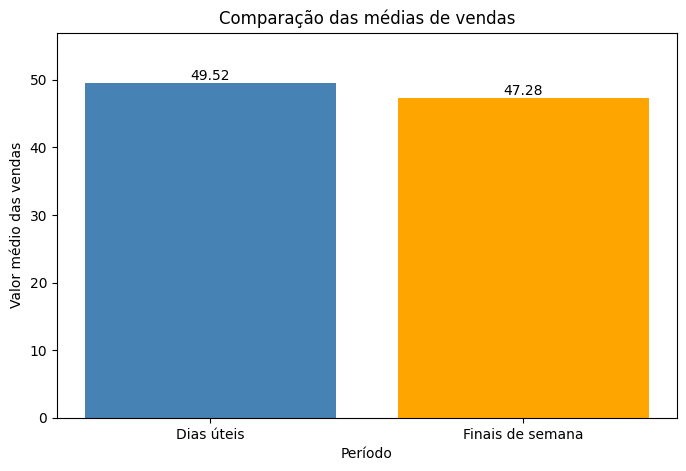

In [9]:
import matplotlib.pyplot as plt

# Valores médios de cada grupo
grupos = ['Dias úteis', 'Finais de semana']
medias = [weekday_sales.mean(), weekend_sales.mean()]

# Criar gráfico
plt.figure(figsize=(8, 5))
plt.bar(grupos, medias, color=['steelblue', 'orange'])

plt.title('Comparação das médias de vendas')
plt.ylabel('Valor médio das vendas')
plt.xlabel('Período')

# Mostrar valores nas barras
for i, media in enumerate(medias):
    plt.text(i, media + 0.5, f'{media:.2f}', ha='center')

plt.ylim(0, max(medias) * 1.15)
plt.show()

In [10]:
# Resumo estatístico dos dois grupos
resumo = pd.DataFrame({
    'Dias úteis': weekday_sales.describe(),
    'Finais de semana': weekend_sales.describe()
})

print("Resumo estatístico das vendas:")
print(resumo.round(2))

Resumo estatístico das vendas:
       Dias úteis  Finais de semana
count       75.00             25.00
mean        49.52             47.28
std          8.62             10.34
min         23.80             30.12
25%         44.69             40.92
50%         49.28             48.62
75%         53.69             55.13
max         65.79             68.52


## Análise e interpretação dos resultados

Foram analisados 100 registros fictícios de vendas, gerados por meio de Python, sendo 75 associados aos dias úteis e 25 aos finais de semana.

A média das vendas nos dias úteis foi de 49,52, enquanto nos finais de semana foi de 47,28. O desvio-padrão foi de 8,62 e 10,34, respectivamente.

Foi aplicado o teste t de Welch unilateral, considerando nível de significância de 5%. O teste apresentou estatística t de -0,9775 e valor-p de 0,8325.

Como o valor-p foi superior a 0,05, não se rejeitou a hipótese nula. Assim, os dados simulados não forneceram evidências estatísticas suficientes de que a média das vendas seja maior nos finais de semana.

A análise utiliza dados fictícios e, portanto, não permite generalizações sobre vendas reais de uma empresa.

In [11]:
# Verificar dados ausentes
print("Dados ausentes:")
print(data.isnull().sum())

# Conferir a quantidade de registros
print("\nTotal de registros:", len(data))

# Verificar a variabilidade dos grupos
print("\nVariância dos dias úteis:", weekday_sales.var())
print("Variância dos finais de semana:", weekend_sales.var())

# Verificar a distribuição dos dados
print("\nTeste de Shapiro-Wilk:")

print("Dias úteis:", stats.shapiro(weekday_sales))
print("Finais de semana:", stats.shapiro(weekend_sales))

Dados ausentes:
Vendas    0
Dia       0
dtype: int64

Total de registros: 100

Variância dos dias úteis: 74.38957584051404
Variância dos finais de semana: 106.91718495286925

Teste de Shapiro-Wilk:
Dias úteis: ShapiroResult(statistic=np.float64(0.98132608897183), pvalue=np.float64(0.3348245886465994))
Finais de semana: ShapiroResult(statistic=np.float64(0.9671110145553631), pvalue=np.float64(0.5730305663841024))
